# Sonar contact detection with Qwen3-VL and QLoRA

I fine-tuned Qwen3-VL-4B to detect contacts in side-scan sonar imagery and return bounding boxes as JSON. The experiment uses 4-bit QLoRA on the language model attention layers, with the vision encoder frozen.

Training, validation and test regions remain spatially separated. Existing annotations are retained; unreviewed empty labels are excluded. Checkpoints are selected by validation loss. Training curves and detection examples document performance and failure cases.



## Configuration


`BATCH_SIZE` controls images per forward/backward pass; effective batch size is `BATCH_SIZE × GRAD_ACCUM`. Evaluation remains single-image.


In [ ]:
from pathlib import Path
import json, time, random, math, hashlib, shutil, csv, subprocess, sys, gc
from datetime import datetime, timezone


MODEL_ID = 'Qwen/Qwen3-VL-4B-Instruct'
MODEL_REVISION = 'ebb281ec70b05090aa6165b016eac8ec08e71b17'
SEED = 42
EPOCHS = 5
LEARNING_RATE = 5e-5
LORA_RANK = 32
LORA_ALPHA = 64
LORA_DROPOUT = 0.05
BATCH_SIZE = 2
GRAD_ACCUM = 2
assert type(BATCH_SIZE) is int and BATCH_SIZE > 0
assert type(GRAD_ACCUM) is int and GRAD_ACCUM > 0
MAX_TRAIN_IMAGES = None
MAX_VAL_IMAGES = None
TRAIN_LOSS_IMAGES = 256
MAX_TRAIN_HOURS = 3.0
MAX_NEW_TOKENS = 512
MATCH_IOU = 0.5
EXAMPLES_PER_CATEGORY = 6
RUN_BASELINE = True
RUN_FINAL_TEST = False
AUTO_DISCONNECT = False

MYDRIVE = Path('/content/drive/MyDrive')
DATA_ZIP = MYDRIVE/'sss_contact_yolo26_spatial_split_A_round2_v001.zip'
PILOT_ZIP = MYDRIVE/'LLM-fine-tuning/Qwen3-VL-4B-contact/pilot_20261015T123717Z/pilot_data.zip'

REVIEWED_NEGATIVES_CSV = None
OUTPUT_ROOT = MYDRIVE/'LLM-fine-tuning/Qwen3-VL-4B-contact'
PROMPT = ('Detect every visible sonar contact in this side-scan sonar image. '
          'All objects belong to one class: contact. Do not classify object types. '
          'Return only JSON: {"boxes": [[x1,y1,x2,y2], ...]}. '
          'Coordinates are integers normalized to 0-1000 relative to the original image, '
          'with origin at the top left. Include all contact bounding boxes, ordered '
          'top to bottom, then left to right. Return {"boxes": []} only if no contacts '
          'are visible. Do not mark ordinary seabed texture or sand-wave ridges as contacts.')
print('Epochs:',EPOCHS,'Train limit:',MAX_TRAIN_IMAGES,'Val limit:',MAX_VAL_IMAGES)
print('Default excludes all unreviewed empty labels. TN requires reviewed negatives.')

print('Microbatch:',BATCH_SIZE,'Accumulation:',GRAD_ACCUM,'Effective batch:',BATCH_SIZE*GRAD_ACCUM)


Epochs: 5 Train limit: None Val limit: None
Default excludes all unreviewed empty labels. TN requires reviewed negatives.
Microbatch: 2 Accumulation: 2 Effective batch: 4


## Dependencies


In [ ]:
import subprocess, sys
assert sys.version_info >= (3,10)
subprocess.check_call([sys.executable,'-m','pip','install','-q','transformers==4.57.6','peft==0.18.1','accelerate==1.15.0','bitsandbytes==0.49.2','huggingface_hub==0.36.2','matplotlib','scipy','pandas','Pillow'])


0

## Runtime and output directory


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import torch
assert torch.cuda.is_available(), 'Select Runtime > Change runtime type > GPU, preferably L4.'
print(subprocess.getoutput('nvidia-smi'))
print('Read current CU balance and CU/hour in Colab Resources before proceeding.')
print('Prior L4 observation was 1.54 CU/hour; this is not a guarantee for this session.')
STAMP=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN=OUTPUT_ROOT/('epochs_v3_'+STAMP)
RUN.mkdir(parents=True,exist_ok=False)
def save_json(name,obj):
    target=RUN/name; target.parent.mkdir(parents=True,exist_ok=True)
    temp=target.with_name(target.name+'.tmp')
    temp.write_text(json.dumps(obj,indent=2,allow_nan=False));temp.replace(target)
print('All outputs will be saved to:',RUN)


Mounted at /content/drive
Fri Oct 16 10:08:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   40C    P8             14W /   72W |       3MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------

## Dataset utilities


In [ ]:
import zipfile
import numpy as np
from PIL import Image

def safe_extract(archive,destination):
    destination=Path(destination); destination.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for item in z.infolist():
            name=item.filename
            if name.startswith('/') or '..' in Path(name).parts or '\\' in name:
                raise ValueError('Unsafe archive member: '+name)
            if (item.external_attr >> 16) & 0o170000 == 0o120000:
                raise ValueError('Archive symlink disallowed: '+name)
        assert z.testzip() is None, 'ZIP integrity check failed'
        z.extractall(destination)

def load_dataset(root,reviewed_negatives=None):
    root=Path(root); reviewed_negatives=reviewed_negatives or set()
    full=list(root.rglob('split_manifest_A_round2_v001.csv'))
    result=[]; skipped={s:0 for s in ['train','val','test','buffer']}
    if full:
        assert len(full)==1,'Multiple dataset manifests'
        bundle=full[0].parent.parent
        for r in csv.DictReader(full[0].open()):
            split=r['final_split']; pid=r['patch_id']
            if split=='buffer':skipped[split]+=1;continue
            label=bundle/'data'/'labels'/split/(pid+'.txt')
            image=bundle/'data'/'images'/split/(pid+'.png')
            assert image.is_file() and label.is_file(),pid
            raw=label.read_bytes()
            if r.get('label_sha256'):
                assert hashlib.sha256(raw).hexdigest()==r['label_sha256'],pid+' label hash mismatch'
            boxes=[]
            for line in raw.decode().splitlines():
                if not line.strip():continue
                c,x,y,w,h=map(float,line.split())
                assert c==0 and w>0 and h>0 and all(math.isfinite(v) for v in [x,y,w,h])
                box=[round(1000*max(0,x-w/2)),round(1000*max(0,y-h/2)),
                     round(1000*min(1,x+w/2)),round(1000*min(1,y+h/2))]
                assert 0<=box[0]<box[2]<=1000 and 0<=box[1]<box[3]<=1000,(pid,box)
                boxes.append(box)
            approved=(pid,split) in reviewed_negatives
            if not boxes and not approved:skipped[split]+=1;continue
            result.append({'patch_id':pid,'split':split,'image':str(image),
                'boxes_1000':sorted(boxes,key=lambda b:(b[1],b[0])),
                'negative_reviewed':bool(approved and not boxes),'label_source':r['label_source'],
                'spatial_chunk':int(r['spatial_chunk']),
                'footprint':[float(r[k]) for k in ['x0','y0','x1','y1']]})
        mode='full_round2_bundle'
    else:
        candidates=list(root.rglob('manifest.json'))
        assert len(candidates)==1,'No supported full/pilot manifest found'
        bundle=candidates[0].parent
        for r in json.loads(candidates[0].read_text()):
            split=r['final_split'];pid=r['patch_id'];image=bundle/r['image']
            assert hashlib.sha256(image.read_bytes()).hexdigest()==r['image_sha256'],pid
            approved=(pid,split) in reviewed_negatives
            if not r['boxes_1000'] and not approved:skipped[split]+=1;continue
            result.append({'patch_id':pid,'split':split,'image':str(image),
                'boxes_1000':r['boxes_1000'],'negative_reviewed':bool(approved and not r['boxes_1000']),
                'label_source':r['label_source'],'spatial_chunk':int(r['spatial_chunk']),
                'footprint':[float(r[k]) for k in ['x0','y0','x1','y1']]})
        mode='64_image_pilot_ONLY'
    keys=[(r['split'],r['patch_id']) for r in result]
    assert len(keys)==len(set(keys)),'Duplicate records'
    return result,mode,skipped

def subsample(rows,limit,seed):
    rows=sorted(rows,key=lambda r:r['patch_id'])
    if limit is None or limit>=len(rows):return rows
    assert limit>0

    groups={}
    for r in rows:groups.setdefault(min(len(r['boxes_1000']),2),[]).append(r)
    rng=random.Random(seed)
    for group in groups.values():rng.shuffle(group)
    picked=[]
    while len(picked)<limit:
        for key in sorted(groups):
            if groups[key] and len(picked)<limit:picked.append(groups[key].pop())
    return sorted(picked,key=lambda r:r['patch_id'])

def minimum_gap(a,b):
    assert a and b
    bb=np.asarray([r['footprint'] for r in b]);answer=float('inf')
    for start in range(0,len(a),128):
        aa=np.asarray([r['footprint'] for r in a[start:start+128]])
        dx=np.maximum(0,np.maximum(aa[:,None,0]-bb[None,:,2],bb[None,:,0]-aa[:,None,2]))
        dy=np.maximum(0,np.maximum(aa[:,None,1]-bb[None,:,3],bb[None,:,1]-aa[:,None,3]))
        answer=min(answer,float(np.sqrt(dx*dx+dy*dy).min()))
    return answer


## Spatial split and annotations


In [ ]:
if not DATA_ZIP.is_file():
    found=sorted(MYDRIVE.rglob(DATA_ZIP.name))
    if len(found)==1:DATA_ZIP=found[0]
    elif len(found)>1:raise ValueError('Multiple full ZIPs found. Set DATA_ZIP explicitly: '+str(found))
    elif PILOT_ZIP.is_file():
        DATA_ZIP=PILOT_ZIP
        print('FULL DATA ZIP NOT FOUND: using the previous 48-train/16-val pilot only.')
    else:
        from google.colab import files
        print('Upload the full round-2 ZIP or pilot_data.zip ONCE; it will be cached on Drive.')
        uploaded=files.upload()
        assert len(uploaded)==1,'Upload exactly one dataset ZIP'
        name,raw=next(iter(uploaded.items()))
        assert name.endswith('.zip')
        DATA_ZIP=OUTPUT_ROOT/'datasets'/Path(name).name
        DATA_ZIP.parent.mkdir(parents=True,exist_ok=True);DATA_ZIP.write_bytes(raw)
        del uploaded,raw
print('Using dataset:',DATA_ZIP)
DATA=Path('/content/sss_contact_epochs_v3')/STAMP
safe_extract(DATA_ZIP,DATA)
reviewed=set()
if REVIEWED_NEGATIVES_CSV is not None:
    with Path(REVIEWED_NEGATIVES_CSV).open() as f:
        reviewed={(r['patch_id'],r['split']) for r in csv.DictReader(f)}
all_rows,DATA_MODE,excluded=load_dataset(DATA,reviewed)
train_rows=subsample([r for r in all_rows if r['split']=='train'],MAX_TRAIN_IMAGES,SEED)
val_rows=subsample([r for r in all_rows if r['split']=='val'],MAX_VAL_IMAGES,SEED)
test_rows=[r for r in all_rows if r['split']=='test']
assert train_rows and val_rows,'Train/validation data required'
gap=minimum_gap(train_rows,val_rows);assert gap>=15-1e-6,('Spatial gap below 15m',gap)
if RUN_FINAL_TEST:
    assert test_rows,'Pilot data has no test split; provide the full bundle.'
    assert minimum_gap(train_rows,test_rows)>=15-1e-6
train_loss_rows=subsample(train_rows,TRAIN_LOSS_IMAGES,SEED+1)
from collections import Counter
stats={s:{'images':len(rr),'boxes':sum(len(r['boxes_1000']) for r in rr),
          'reviewed_negatives':sum(r['negative_reviewed'] for r in rr),
          'multi_contact_images':sum(len(r['boxes_1000'])>1 for r in rr)}
       for s,rr in [('train',train_rows),('val',val_rows),('test_available',test_rows)]}
print('DATA MODE:',DATA_MODE);print(json.dumps(stats,indent=2));print('Minimum train/val footprint gap:',gap,'m')
print('Unreviewed empty labels excluded:',excluded)
print('Fixed train-loss monitoring subset:',len(train_loss_rows))
save_json('dataset_summary.json',{'mode':DATA_MODE,'zip':str(DATA_ZIP),'counts':stats,
    'excluded':excluded,'min_train_val_gap_m':gap,'train_loss_images':len(train_loss_rows),
    'test_labels_note':'Full bundle test chunks retain original labels; no new relabeling is performed.'})
save_json('selected_manifest.json',{'train':train_rows,'val':val_rows,
    'train_loss_monitor_ids':[r['patch_id'] for r in train_loss_rows],
    'test':test_rows if RUN_FINAL_TEST else []})


Using dataset: /content/drive/MyDrive/sss_contact_yolo26_spatial_split_A_round2_v001.zip
DATA MODE: full_round2_bundle
{
  "train": {
    "images": 1732,
    "boxes": 2528,
    "reviewed_negatives": 0,
    "multi_contact_images": 494
  },
  "val": {
    "images": 276,
    "boxes": 372,
    "reviewed_negatives": 0,
    "multi_contact_images": 53
  },
  "test_available": {
    "images": 125,
    "boxes": 167,
    "reviewed_negatives": 0,
    "multi_contact_images": 29
  }
}
Minimum train/val footprint gap: 35.0 m
Unreviewed empty labels excluded: {'train': 5115, 'val': 1420, 'test': 1480, 'buffer': 608}
Fixed train-loss monitoring subset: 256


## Quantized base model


In [ ]:
import importlib.metadata as metadata
from transformers import AutoProcessor,Qwen3VLForConditionalGeneration,BitsAndBytesConfig
from peft import LoraConfig,get_peft_model,prepare_model_for_kbit_training
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED);torch.cuda.manual_seed_all(SEED)
DTYPE=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
CONFIG={k:globals()[k] for k in ['MODEL_ID','MODEL_REVISION','SEED','EPOCHS','LEARNING_RATE',
    'LORA_RANK','LORA_ALPHA','LORA_DROPOUT','BATCH_SIZE','GRAD_ACCUM','MAX_TRAIN_IMAGES','MAX_VAL_IMAGES',
    'TRAIN_LOSS_IMAGES','MAX_TRAIN_HOURS','MAX_NEW_TOKENS','MATCH_IOU','RUN_BASELINE',
    'RUN_FINAL_TEST','AUTO_DISCONNECT','PROMPT']}
save_json('config.json',CONFIG)
save_json('versions.json',{p:metadata.version(p) for p in ['torch','transformers','peft',
    'accelerate','bitsandbytes','numpy','scipy','matplotlib','Pillow']})
(RUN/'pip_freeze.txt').write_text(subprocess.getoutput(f'{sys.executable} -m pip freeze'))
processor=AutoProcessor.from_pretrained(MODEL_ID,revision=MODEL_REVISION,
    min_pixels=256*256,max_pixels=256*256)
processor.tokenizer.padding_side='right'
print('Downloading/loading pinned model revision:',MODEL_REVISION,flush=True)
model=Qwen3VLForConditionalGeneration.from_pretrained(MODEL_ID,revision=MODEL_REVISION,
    quantization_config=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type='nf4',
       bnb_4bit_use_double_quant=True,bnb_4bit_compute_dtype=DTYPE),
    torch_dtype=DTYPE,device_map={'':0},attn_implementation='sdpa')

model=prepare_model_for_kbit_training(model,use_gradient_checkpointing=True,
    gradient_checkpointing_kwargs={'use_reentrant':False})
print('Base model ready. Vision encoder remains frozen.')


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

model-00002-of-00002.safetensors:   0%|          | 0.00/3.91G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

Base model ready. Vision encoder remains frozen.


## Encoding and evaluation


In [ ]:
def encode(r,answer=False):
    msg=[{'role':'user','content':[{'type':'image'},{'type':'text','text':PROMPT}]}]
    if answer:msg.append({'role':'assistant','content':json.dumps({'boxes':r['boxes_1000']},separators=(',',':'))})
    text=processor.apply_chat_template(msg,tokenize=False,add_generation_prompt=not answer)
    with Image.open(r['image']) as im:image=im.convert('RGB')
    b=processor(text=[text],images=[image],return_tensors='pt');b.pop('token_type_ids',None)
    if answer:
        prefix=encode(r)['input_ids'];n=prefix.shape[1]
        assert torch.equal(b['input_ids'][:,:n],prefix),'Assistant-prefix masking mismatch'
        b['labels']=b['input_ids'].clone();b['labels'][:,:n]=-100
        assert (b['labels'][:,1:]!=-100).sum()>0
    return b

def parse_boxes(text):
    import re
    try:
        text=text.strip()
        if text.startswith('```'):text=re.sub(r'^```(?:json)?\s*|\s*```$','',text)
        d=json.loads(text)
        if not isinstance(d,dict) or set(d)!={'boxes'} or not isinstance(d['boxes'],list):return [],False
        for b in d['boxes']:
            if not isinstance(b,list) or len(b)!=4:return [],False
            if any(isinstance(v,bool) or not isinstance(v,(int,float)) or not math.isfinite(v) for v in b):return [],False
            if not(0<=b[0]<b[2]<=1000 and 0<=b[1]<b[3]<=1000):return [],False
        return d['boxes'],True
    except (ValueError,TypeError):return [],False

def box_iou(a,b):
    intersection=max(0,min(a[2],b[2])-max(a[0],b[0]))*max(0,min(a[3],b[3])-max(a[1],b[1]))
    union=(a[2]-a[0])*(a[3]-a[1])+(b[2]-b[0])*(b[3]-b[1])-intersection
    return intersection/union if union>0 else 0.0

def match_boxes(pred,gt,threshold):
    from scipy.optimize import linear_sum_assignment
    pairs=[]
    if pred and gt:
        mat=np.array([[box_iou(p,g) for g in gt] for p in pred])
        score=(mat>=threshold)*(min(len(pred),len(gt))+1)+mat
        ii,jj=linear_sum_assignment(score,maximize=True)
        pairs=[(int(i),int(j),float(mat[i,j])) for i,j in zip(ii,jj) if mat[i,j]>=threshold]
    used_p={p[0] for p in pairs};used_g={p[1] for p in pairs}
    return pairs,[i for i in range(len(pred)) if i not in used_p],[j for j in range(len(gt)) if j not in used_g]

def summarize_detection(predictions,threshold):
    tp=fp=fn=tn=reviewed_empty=invalid=0
    for p in predictions:
        pairs,extra,missed=match_boxes(p['boxes'],p['ground_truth'],threshold)
        tp+=len(pairs);fp+=len(extra);fn+=len(missed);invalid+=not p['valid_json']
        if p['negative_reviewed'] and not p['ground_truth']:
            reviewed_empty+=1
            tn+=int(p['valid_json'] and not p['boxes'] and not p['hit_token_limit'])
    precision=tp/(tp+fp) if tp+fp else 0.0;recall=tp/(tp+fn) if tp+fn else 0.0
    return {'iou':threshold,'tp_boxes':tp,'fp_boxes':fp,'fn_boxes':fn,
        'precision':precision,'recall':recall,'f1':2*precision*recall/(precision+recall) if precision+recall else 0.0,
        'tn_images':tn if reviewed_empty else None,'reviewed_negative_images':reviewed_empty,
        'invalid_json_images':invalid,'images':len(predictions),
        'note':'TP/FP/FN are box counts; TN is an image count, not a detection-box TN. Invalid output is never TN.'}

@torch.inference_mode()
def measure_loss(rows,label):

    was_training=model.training;model.eval();model.config.use_cache=False
    total=0.0;tokens=0
    for i,r in enumerate(rows):
        b={k:v.to('cuda') for k,v in encode(r,True).items()}
        n=int((b['labels'][:,1:]!=-100).sum().item())
        with torch.autocast('cuda',dtype=DTYPE):loss=model(**b).loss
        value=float(loss.float().item());assert math.isfinite(value),'Non-finite evaluation loss'
        total+=value*n;tokens+=n
        del b,loss
        if (i+1)%100==0:print(label,i+1,'/',len(rows),flush=True)
    model.train(was_training)
    return total/tokens

@torch.inference_mode()
def predict(rows,tag):
    model.eval();model.config.use_cache=True;model.gradient_checkpointing_disable()
    predictions=[];started=time.monotonic()
    for i,r in enumerate(rows):
        b={k:v.to('cuda') for k,v in encode(r).items()}
        ids=model.generate(**b,max_new_tokens=MAX_NEW_TOKENS,do_sample=False,use_cache=True)
        tail=ids[:,b['input_ids'].shape[1]:]
        text=processor.batch_decode(tail,skip_special_tokens=True,clean_up_tokenization_spaces=False)[0]
        boxes,valid=parse_boxes(text)
        predictions.append({'patch_id':r['patch_id'],'image':r['image'],'boxes':boxes,
            'ground_truth':r['boxes_1000'],'negative_reviewed':r['negative_reviewed'],
            'valid_json':valid,'raw_text':text,'hit_token_limit':tail.shape[1]>=MAX_NEW_TOKENS})
        if (i+1)%10==0 or i+1==len(rows):
            save_json(tag+'_predictions.json',predictions)
            print(tag,i+1,'/',len(rows),flush=True)
        del b,ids,tail
    metrics=[summarize_detection(predictions,t) for t in [0.25,0.5,0.75]]
    save_json(tag+'_metrics.json',{'metrics':metrics,'seconds':time.monotonic()-started,
        'json_valid_rate':sum(p['valid_json'] for p in predictions)/len(predictions),
        'token_limit_images':sum(p['hit_token_limit'] for p in predictions)})
    return predictions,metrics

def collate_training_samples(samples):
    assert samples
    expected={'input_ids','attention_mask','labels','pixel_values','image_grid_thw'}
    assert all(set(s)==expected for s in samples), 'Unexpected processor fields; check batching before training.'
    if len(samples)==1:
        return samples[0]
    pad_id=processor.tokenizer.pad_token_id
    assert pad_id is not None
    assert processor.tokenizer.padding_side=='right'
    result={}
    for key,padding in [('input_ids',pad_id),('attention_mask',0),('labels',-100)]:
        result[key]=torch.nn.utils.rnn.pad_sequence(
            [s[key].squeeze(0) for s in samples],batch_first=True,padding_value=padding)
    # Image patches and grids follow the same sample order as the text batch.
    for key in ['pixel_values','image_grid_thw']:
        result[key]=torch.cat([s[key] for s in samples],dim=0)
    assert torch.all(result['labels'][result['attention_mask']==0]==-100)
    return result


## Baseline


In [ ]:
history=[{'epoch':0,'train_loss':measure_loss(train_loss_rows,'train loss epoch 0'),
          'val_loss':measure_loss(val_rows,'val loss epoch 0')}]
save_json('loss_history.json',history)
if RUN_BASELINE:
    baseline_predictions,baseline_metrics=predict(val_rows,'baseline_val')
    print('Baseline IoU 0.5:',baseline_metrics[1])
print('Initial loss:',history[0])


train loss epoch 0 100 / 256
train loss epoch 0 200 / 256
val loss epoch 0 100 / 276
val loss epoch 0 200 / 276


The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


baseline_val 10 / 276
baseline_val 20 / 276
baseline_val 30 / 276
baseline_val 40 / 276
baseline_val 50 / 276
baseline_val 60 / 276
baseline_val 70 / 276
baseline_val 80 / 276
baseline_val 90 / 276
baseline_val 100 / 276
baseline_val 110 / 276
baseline_val 120 / 276
baseline_val 130 / 276
baseline_val 140 / 276
baseline_val 150 / 276
baseline_val 160 / 276
baseline_val 170 / 276
baseline_val 180 / 276
baseline_val 190 / 276
baseline_val 200 / 276
baseline_val 210 / 276
baseline_val 220 / 276
baseline_val 230 / 276
baseline_val 240 / 276
baseline_val 250 / 276
baseline_val 260 / 276
baseline_val 270 / 276
baseline_val 276 / 276
Baseline IoU 0.5: {'iou': 0.5, 'tp_boxes': 1, 'fp_boxes': 11, 'fn_boxes': 371, 'precision': 0.08333333333333333, 'recall': 0.002688172043010753, 'f1': 0.005208333333333334, 'tn_images': None, 'reviewed_negative_images': 0, 'invalid_json_images': 0, 'images': 276, 'note': 'TP/FP/FN are box counts; TN is an image count, not a detection-box TN. Invalid output is nev

## QLoRA training


In [ ]:
targets=[n for n,m in model.named_modules() if 'language_model' in n and
         n.rsplit('.',1)[-1] in {'q_proj','k_proj','v_proj','o_proj'}]
assert targets and not any('visual' in n for n in targets)
model=get_peft_model(model,LoraConfig(r=LORA_RANK,lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,bias='none',task_type='CAUSAL_LM',target_modules=targets))
assert all('lora_' in n and 'language_model' in n for n,p in model.named_parameters() if p.requires_grad)
model.print_trainable_parameters()
save_json('trainable_modules.json',targets)
params=[p for p in model.parameters() if p.requires_grad]
optimizer=torch.optim.AdamW(params,lr=LEARNING_RATE,weight_decay=0.01)
scaler=torch.amp.GradScaler('cuda',enabled=DTYPE==torch.float16)
step_log=[];best_val=float('inf');best_epoch=None;steps=0;stopped=False
start_training=time.monotonic();torch.cuda.reset_peak_memory_stats()
for epoch in range(1,EPOCHS+1):
    if time.monotonic()-start_training>MAX_TRAIN_HOURS*3600:stopped=True;break
    model.train();model.config.use_cache=False
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant':False})
    order=list(range(len(train_rows)));random.Random(SEED+epoch).shuffle(order)
    epoch_loss_sum=0.0;epoch_tokens=0
    for pos in range(0,len(order),BATCH_SIZE*GRAD_ACCUM):
        if time.monotonic()-start_training>MAX_TRAIN_HOURS*3600:
            stopped=True;break
        group_indices=order[pos:pos+BATCH_SIZE*GRAD_ACCUM]
        group=[collate_training_samples([encode(train_rows[i],True) for i in group_indices[j:j+BATCH_SIZE]])
               for j in range(0,len(group_indices),BATCH_SIZE)]
        counts=[int((b['labels'][:,1:]!=-100).sum().item()) for b in group]
        group_tokens=sum(counts);optimizer.zero_grad(set_to_none=True)
        group_loss_sum=0.0
        for cpu_batch,n in zip(group,counts):
            batch={k:v.to('cuda') for k,v in cpu_batch.items()}
            with torch.autocast('cuda',dtype=DTYPE):loss=model(**batch).loss
            value=float(loss.detach().float().item());assert math.isfinite(value),'Non-finite training loss'

            scaler.scale(loss*(n/group_tokens)).backward()
            group_loss_sum+=value*n;epoch_loss_sum+=value*n;epoch_tokens+=n
            del batch,loss
        scaler.unscale_(optimizer);norm=torch.nn.utils.clip_grad_norm_(params,1.0)
        assert torch.isfinite(norm).item(),'Non-finite gradient'
        scaler.step(optimizer);scaler.update();steps+=1
        step_log.append({'epoch':epoch,'step':steps,'online_train_loss':group_loss_sum/group_tokens,
                         'examples_seen_this_epoch':min(pos+len(group_indices),len(order))})
        if steps%25==0:
            save_json('step_log.json',step_log)
            print('Epoch',epoch,'/',EPOCHS,'image',min(pos+len(group_indices),len(order)),'/',len(order),
                  'loss',round(group_loss_sum/group_tokens,4),flush=True)
        del group
    if stopped:
        model.save_pretrained(RUN/'adapter_partial',safe_serialization=True)
        processor.save_pretrained(RUN/'adapter_partial')
        print('Time budget reached mid-epoch. Partial weights saved; no fabricated epoch point.')
        break
    train_loss=measure_loss(train_loss_rows,f'train loss epoch {epoch}')
    val_loss=measure_loss(val_rows,f'val loss epoch {epoch}')
    entry={'epoch':epoch,'train_loss':train_loss,'val_loss':val_loss,
        'online_train_loss':epoch_loss_sum/epoch_tokens,'optimizer_steps':steps,
        'elapsed_seconds':time.monotonic()-start_training}
    history.append(entry);save_json('loss_history.json',history);save_json('step_log.json',step_log)
    folder=RUN/f'adapter_epoch_{epoch:02d}'
    model.save_pretrained(folder,safe_serialization=True);processor.save_pretrained(folder)
    if val_loss<best_val:
        best_val=val_loss;best_epoch=epoch
        model.save_pretrained(RUN/'adapter_best',safe_serialization=True)
        processor.save_pretrained(RUN/'adapter_best')
    print('EPOCH COMPLETE:',json.dumps(entry),flush=True)
assert best_epoch is not None,'No complete epoch. Increase time budget or reduce MAX_TRAIN_IMAGES.'
save_json('training_summary.json',{'completed_epochs':len(history)-1,'best_epoch':best_epoch,
    'best_val_loss':best_val,'optimizer_steps':steps,'time_budget_stop':stopped,
    'training_seconds':time.monotonic()-start_training,
    'peak_vram_gib':torch.cuda.max_memory_allocated()/2**30})
del optimizer;gc.collect();torch.cuda.empty_cache()


trainable params: 23,592,960 || all params: 4,461,408,768 || trainable%: 0.5288
Epoch 1 / 5 image 100 / 1732 loss 1.2874
Epoch 1 / 5 image 200 / 1732 loss 1.0686
Epoch 1 / 5 image 300 / 1732 loss 0.8467
Epoch 1 / 5 image 400 / 1732 loss 0.8496
Epoch 1 / 5 image 500 / 1732 loss 1.0031
Epoch 1 / 5 image 600 / 1732 loss 1.0558
Epoch 1 / 5 image 700 / 1732 loss 0.9977
Epoch 1 / 5 image 800 / 1732 loss 0.9363
Epoch 1 / 5 image 900 / 1732 loss 1.043
Epoch 1 / 5 image 1000 / 1732 loss 0.8632
Epoch 1 / 5 image 1100 / 1732 loss 0.8845
Epoch 1 / 5 image 1200 / 1732 loss 0.7342
Epoch 1 / 5 image 1300 / 1732 loss 0.9242
Epoch 1 / 5 image 1400 / 1732 loss 0.7945
Epoch 1 / 5 image 1500 / 1732 loss 0.9707
Epoch 1 / 5 image 1600 / 1732 loss 0.7359
Epoch 1 / 5 image 1700 / 1732 loss 1.1083
train loss epoch 1 100 / 256
train loss epoch 1 200 / 256
val loss epoch 1 100 / 276
val loss epoch 1 200 / 276
EPOCH COMPLETE: {"epoch": 1, "train_loss": 0.9674757350516575, "val_loss": 0.9108584564958264, "online_t

## Loss curves


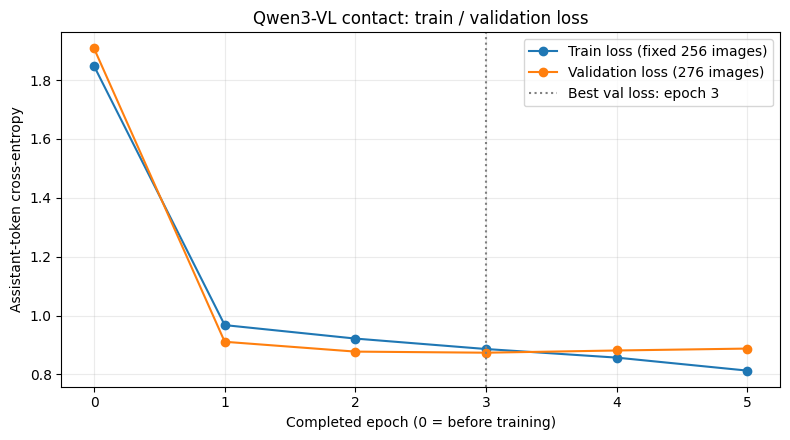

Solid curves use eval mode on both sets; dropout is off. Online training loss is logged separately.


In [ ]:
import matplotlib.pyplot as plt
from IPython.display import display
fig,ax=plt.subplots(figsize=(8,4.5))
ax.plot([h['epoch'] for h in history],[h['train_loss'] for h in history],'-o',label=f'Train loss (fixed {len(train_loss_rows)} images)')
ax.plot([h['epoch'] for h in history],[h['val_loss'] for h in history],'-o',label=f'Validation loss ({len(val_rows)} images)')
ax.axvline(best_epoch,color='gray',linestyle=':',label=f'Best val loss: epoch {best_epoch}')
ax.set(xlabel='Completed epoch (0 = before training)',ylabel='Assistant-token cross-entropy',
       title='Qwen3-VL contact: train / validation loss')
ax.set_xticks([h['epoch'] for h in history]);ax.grid(alpha=.25);ax.legend()
fig.tight_layout();fig.savefig(RUN/'loss_curves.png',dpi=180);fig.savefig(RUN/'loss_curves.pdf')
plt.show()
with (RUN/'loss_history.csv').open('w',newline='') as f:
    fields=sorted(set().union(*(h.keys() for h in history)))
    writer=csv.DictWriter(f,fieldnames=fields);writer.writeheader();writer.writerows(history)
print('Solid curves use eval mode on both sets; dropout is off. Online training loss is logged separately.')


## Saved-checkpoint evaluation


In [ ]:
model.load_adapter(str(RUN/'adapter_best'),adapter_name='saved_best',is_trainable=False)
model.set_adapter('saved_best');model.eval();model.gradient_checkpointing_disable()
val_predictions,val_metrics=predict(val_rows,'finetuned_val')
print('Best checkpoint: epoch',best_epoch,'IoU 0.5:',val_metrics[1])
if RUN_FINAL_TEST:
    test_predictions,test_metrics=predict(test_rows,'finetuned_test')
    print('Final test IoU 0.5:',test_metrics[1])


/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:468: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


finetuned_val 10 / 276
finetuned_val 20 / 276
finetuned_val 30 / 276
finetuned_val 40 / 276
finetuned_val 50 / 276
finetuned_val 60 / 276
finetuned_val 70 / 276
finetuned_val 80 / 276
finetuned_val 90 / 276
finetuned_val 100 / 276
finetuned_val 110 / 276
finetuned_val 120 / 276
finetuned_val 130 / 276
finetuned_val 140 / 276
finetuned_val 150 / 276
finetuned_val 160 / 276
finetuned_val 170 / 276
finetuned_val 180 / 276
finetuned_val 190 / 276
finetuned_val 200 / 276
finetuned_val 210 / 276
finetuned_val 220 / 276
finetuned_val 230 / 276
finetuned_val 240 / 276
finetuned_val 250 / 276
finetuned_val 260 / 276
finetuned_val 270 / 276
finetuned_val 276 / 276
Best checkpoint: epoch 3 IoU 0.5: {'iou': 0.5, 'tp_boxes': 205, 'fp_boxes': 146, 'fn_boxes': 167, 'precision': 0.584045584045584, 'recall': 0.5510752688172043, 'f1': 0.5670816044260027, 'tn_images': None, 'reviewed_negative_images': 0, 'invalid_json_images': 0, 'images': 276, 'note': 'TP/FP/FN are box counts; TN is an image count, not 

## Detection examples

Green: matched prediction; dashed green: matched annotation; red: unmatched prediction; yellow: missed annotation. TN requires reviewed negative images.


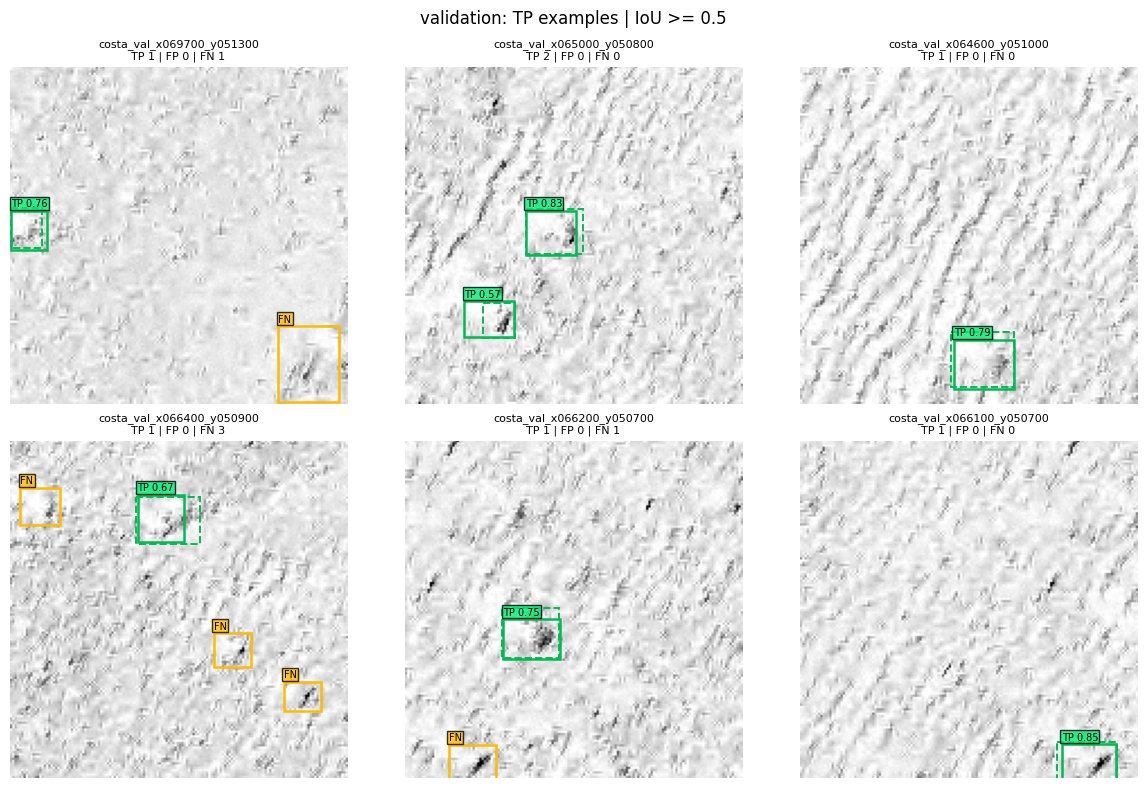

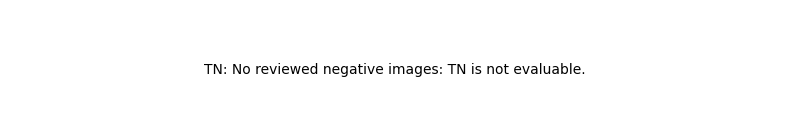

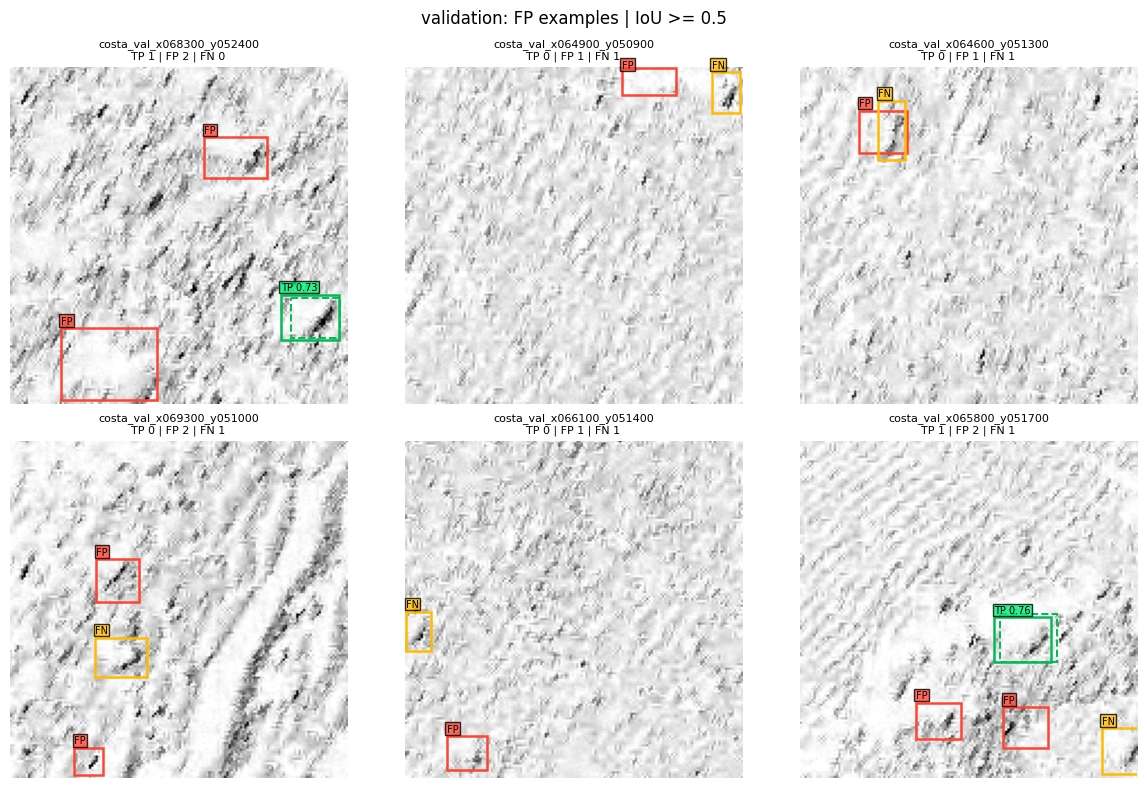

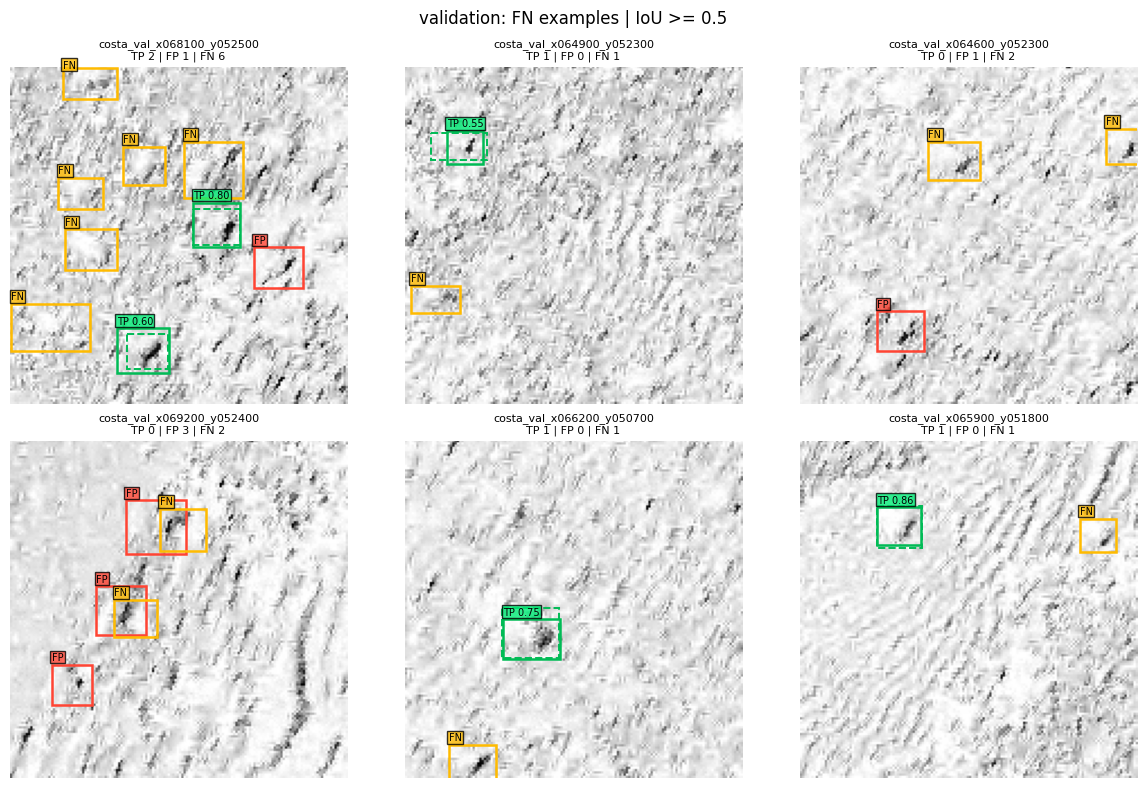

Green solid = matched prediction; green dashed = its GT. Red = unmatched prediction; yellow = unmatched GT.
One image can contain TP, FP and FN together. TN is image-level only.


,model,split,iou,tp_boxes,fp_boxes,fn_boxes,precision,recall,f1,tn_images,reviewed_negative_images,invalid_json_images,images,note
0,Before,val,0.25,4,8,368,0.333333,0.010753,0.020833,None,0,0,276,"TP/FP/FN are box counts; TN is an image count,..."
1,Before,val,0.50,1,11,371,0.083333,0.002688,0.005208,None,0,0,276,"TP/FP/FN are box counts; TN is an image count,..."
2,Before,val,0.75,0,12,372,0.000000,0.000000,0.000000,None,0,0,276,"TP/FP/FN are box counts; TN is an image count,..."
3,After (best val loss),val,0.25,244,107,128,0.695157,0.655914,0.674965,None,0,0,276,"TP/FP/FN are box counts; TN is an image count,..."
4,After (best val loss),val,0.50,205,146,167,0.584046,0.551075,0.567082,None,0,0,276,"TP/FP/FN are box counts; TN is an image count,..."
5,After (best val loss),val,0.75,80,271,292,0.227920,0.215054,0.221300,None,0,0,276,"TP/FP/FN are box counts; TN is an image count,..."


In [ ]:
from matplotlib.patches import Rectangle

def categories(p):
    pairs,fp,fn=match_boxes(p['boxes'],p['ground_truth'],MATCH_IOU)
    names=[]
    if pairs:names.append('TP')
    if fp:names.append('FP')
    if fn:names.append('FN')
    if (p['negative_reviewed'] and not p['ground_truth'] and not p['boxes']
        and p['valid_json'] and not p['hit_token_limit']):names.append('TN')
    return names,pairs,fp,fn

def draw_detection(ax,p):
    with Image.open(p['image']) as im:
        w,h=im.size;ax.imshow(im.convert('RGB'))
    names,pairs,fp,fn=categories(p)
    for i,j,score in pairs:
        g=p['ground_truth'][j];b=p['boxes'][i]
        ax.add_patch(Rectangle((g[0]*w/1000,g[1]*h/1000),(g[2]-g[0])*w/1000,(g[3]-g[1])*h/1000,
                               fill=False,edgecolor='#00bb55',linestyle='--',linewidth=1.4))
        ax.add_patch(Rectangle((b[0]*w/1000,b[1]*h/1000),(b[2]-b[0])*w/1000,(b[3]-b[1])*h/1000,
                               fill=False,edgecolor='#00bb55',linewidth=1.8))
        ax.text(b[0]*w/1000,max(0,b[1]*h/1000-2),f'TP {score:.2f}',color='black',fontsize=7,
                bbox=dict(facecolor='#00ee77',alpha=.8,pad=1))
    for indices,key,color,boxes in [(fp,'FP','#ff4433',p['boxes']),(fn,'FN','#ffbb00',p['ground_truth'])]:
        for j in indices:
            b=boxes[j]
            ax.add_patch(Rectangle((b[0]*w/1000,b[1]*h/1000),(b[2]-b[0])*w/1000,(b[3]-b[1])*h/1000,
                                   fill=False,edgecolor=color,linewidth=1.8))
            ax.text(b[0]*w/1000,max(0,b[1]*h/1000-2),key,color='black',fontsize=7,
                    bbox=dict(facecolor=color,alpha=.8,pad=1))
    note='TN: reviewed background' if 'TN' in names else f'TP {len(pairs)} | FP {len(fp)} | FN {len(fn)}'
    if not p['valid_json']:note+=' | INVALID JSON'
    if p['hit_token_limit']:note+=' | TRUNCATED'
    ax.set_title(p['patch_id']+'\n'+note,fontsize=8);ax.axis('off')

def show_examples(predictions,tag):
    destination=RUN/'examples'/tag;destination.mkdir(parents=True,exist_ok=True)
    chosen={}
    for category in ['TP','TN','FP','FN']:
        candidates=[p for p in predictions if category in categories(p)[0]]

        pool=random.Random(SEED).sample(candidates,min(EXAMPLES_PER_CATEGORY,len(candidates)))
        chosen[category]=[p['patch_id'] for p in pool]
        if not pool:
            explanation=('No reviewed negative images: TN is not evaluable.' if category=='TN' and
                         not any(p['negative_reviewed'] for p in predictions) else 'No examples in this category.')
            fig,ax=plt.subplots(figsize=(8,1.5));ax.axis('off');ax.text(.5,.5,category+': '+explanation,ha='center',va='center',wrap=True)
        else:
            ncols=min(3,len(pool));nrows=math.ceil(len(pool)/ncols)
            fig,axs=plt.subplots(nrows,ncols,figsize=(4*ncols,4*nrows),squeeze=False)
            for ax,p in zip(axs.flat,pool):draw_detection(ax,p)
            for ax in list(axs.flat)[len(pool):]:ax.axis('off')
            fig.suptitle(f'{tag}: {category} examples | IoU >= {MATCH_IOU}',fontsize=12)
        fig.tight_layout();fig.savefig(destination/(category+'.png'),dpi=180,bbox_inches='tight');plt.show()
    save_json('examples/'+tag+'/selected_examples.json',chosen)
    print('Green solid = matched prediction; green dashed = its GT. Red = unmatched prediction; yellow = unmatched GT.')
    print('One image can contain TP, FP and FN together. TN is image-level only.')

show_examples(val_predictions,'validation')
if RUN_FINAL_TEST:show_examples(test_predictions,'test')
import pandas as pd
table=[]
if RUN_BASELINE:
    table.extend({'model':'Before','split':'val',**m} for m in baseline_metrics)
table.extend({'model':'After (best val loss)','split':'val',**m} for m in val_metrics)
if RUN_FINAL_TEST:table.extend({'model':'After','split':'test',**m} for m in test_metrics)
display(pd.DataFrame(table));pd.DataFrame(table).to_csv(RUN/'detection_metrics.csv',index=False)


## Saved artifacts

Automatic runtime release is optional and disabled by default.


In [ ]:
assert (RUN/'adapter_best'/'adapter_model.safetensors').is_file()
assert (RUN/'loss_curves.png').is_file()
assert all((RUN/'examples'/'validation'/(s+'.png')).is_file() for s in ['TP','TN','FP','FN'])
save_json('complete.json',{'status':'complete','run':str(RUN),'best_epoch':best_epoch,
    'validation_images':len(val_rows),'test_evaluated':RUN_FINAL_TEST,
    'tn_evaluable':any(r['negative_reviewed'] for r in val_rows),
    'limitations':['Evaluation is relative to existing labels, which may omit targets.',
                  'Unreviewed empty labels excluded; TN requires confirmed negative images.',
                  'Overlapping patches can repeat targets within a split; these are patch-level metrics.',
                  'Generative coordinates have no detection confidence scores; no AP/mAP claimed.']})
print('DONE. Model, epoch loss curves, CSV metrics and TP/TN/FP/FN galleries saved to:',RUN)
print('The original source data and previous pilot adapter were not overwritten.')
if AUTO_DISCONNECT:
    from google.colab import runtime
    print('Releasing runtime now. Notebook outputs and Drive files remain available.')
    runtime.unassign()


DONE. Model, epoch loss curves, CSV metrics and TP/TN/FP/FN galleries saved to: /content/drive/MyDrive/LLM-fine-tuning/Qwen3-VL-4B-contact/epochs_v3_20261016T100839_368773Z
The original source data and previous pilot adapter were not overwritten.
